# Grammar Scoring Engine for Spoken English

**Task.** Predict a continuous grammar score (0–5, MOS Likert) for a 45–60 s spoken-English recording.
**Metrics.** Pearson correlation and RMSE.

---

## Report

### 1. Approach
Grammar is a property of *what* is said, so the core signal comes from a transcript. Some grammatical
struggle is also audible, though: mid-clause pauses, restarts and slow delivery. The engine combines both
modalities in a stacked ensemble whose components are interpretable on their own.

| Block | Source | What it captures | Interpretability |
|---|---|---|---|
| **Linguistic statistics** | spaCy parse of the Whisper transcript | sentence length, syntactic depth, subordinate clauses, fragments, subject–verb agreement errors, fillers, repetitions, lexical diversity | high: each feature maps onto a rubric line |
| **GEC edit rate** | T5 grammatical-error-correction model | % of words that must change to make the transcript grammatical | high: errors can be shown word-for-word |
| **Prosody / fluency** | raw audio (librosa) | speech rate, pause frequency and length, pitch and energy variation | high |
| **LLM rubric grader** | Gemini (flash-lite), given the rubric | rater-style overall score, accuracy, complexity, error count | high: every score comes with a written rationale |
| **Text embedding** | all-mpnet-base-v2 | overall language quality and register | low |
| **Audio embeddings** | WavLM-base-plus (13 layers, mean) and **WavLM-large** (25 layers, mean + std), all layers concatenated | acoustic, phonetic and rhythmic patterns of proficiency | low |

### 2. Preprocessing
* **Data-quality gate.** The 37 training files labelled 0 turned out to be speech buried in broadband noise. Median
  spectral flatness is 0.51–0.56 for these files and at most 0.17 for every genuine recording. A fixed threshold of
  0.35 predicts 0 for them, and the grammar models are trained only on the 732 genuine recordings.
* Audio is resampled to 16 kHz mono (what Whisper and WavLM expect); no denoising, so pauses and hesitations survive.
* Transcription: `whisper-large-v3-turbo`, English, greedy decoding, 30 s chunks. Whisper keeps learner errors
  (e.g. *"He don't like the food, me and him goes…"*) but can drop some fillers, which is why the audio-based fluency
  features are kept as a complement.
* Transcripts are sentence-split with spaCy. The GEC model corrects one sentence at a time, and edits are counted at
  word level after lower-casing and removing punctuation, so punctuation and casing choices are not counted as errors.
* Every expensive step is cached per file in `cache/*.parquet`, so re-running the notebook takes seconds.

### 3. Pipeline architecture
```
.wav
 ├─ noise gate: spectral flatness > 0.35 ──────────────────────────────────────────────► score 0
 └─ genuine speech
     ├─ Whisper transcript ─┬─ spaCy linguistic stats ─┐
     │                      ├─ T5 GEC edit rate ───────┼─ handcrafted table (38) ─► LightGBM, Ridge ─┐
     │                      ├─ Gemini rubric grades ───┤                                             │
     │                      │        └──────────────────────────────────────────► Ridge ─────────────┤
     │                      └─ mpnet embedding (768) ───────────────────────────► Ridge ─────────────┤
     ├─ librosa pauses / pitch / energy ───────────────┘                                             ├─► non-negative
     ├─ WavLM-base  (13 layers × 768, mean)  ───────────────────────────────────► Ridge, SVR ────────┤   linear stacker
     └─ WavLM-large (25 layers × 1024, mean + std) ─────────────────────────────► Ridge, SVR ────────┘   ─► score 0–5
```
Base models are trained with **5-fold × 3-repeat stratified CV**. Their out-of-fold predictions train the stacker,
and the stacker is scored with its own outer CV so the reported ensemble score is not optimistic.

### 4. Evaluation results
See **Section 9** (cross-validation) and **Section 10** (training RMSE, compulsory). Summary table:

| Model | CV RMSE | CV Pearson |
|---|---|---|
| Baseline (predict the mean) | 1.014 | n/a |
| Handcrafted features (incl. LLM grades) · LightGBM | 0.659 | 0.760 |
| Handcrafted features (incl. LLM grades) · Ridge | 0.686 | 0.737 |
| Text embedding (mpnet) · Ridge | 0.746 | 0.679 |
| LLM rubric grades · Ridge | 0.732 | 0.692 |
| WavLM-base, all layers · Ridge | 0.533 | 0.851 |
| WavLM-base, all layers · SVR | 0.539 | 0.852 |
| WavLM-large, all layers mean+std · Ridge | 0.491 | 0.875 |
| WavLM-large, all layers mean · SVR | 0.507 | 0.870 |
| **Stacked ensemble, 732 genuine recordings** | **0.472** | **0.885** |
| **Gate + ensemble, all 769 training files** | **0.461** | **0.928** |
| **Training RMSE (compulsory), all 769 files, full fit** | **0.161** | 0.992 |

Version history (CV on genuine recordings): v1 0.542 / 0.845 → v2 with LLM grader 0.530 / 0.853 → **v3 with
WavLM-large and all-layer pooling 0.472 / 0.885**. 5-fold × 3-repeat stratified CV; the stacker is scored with its own
outer CV. Training RMSE measures fit (the high-dimensional Ridge models fit training data closely), while the
CV figures estimate test performance.

## 0. Setup

In [1]:
import sys, warnings
from pathlib import Path

# Find the project root (the folder containing src/) whether we run from notebooks/ or the repo root.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(PROJECT_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold

import lightgbm  # noqa: F401 - must load before PyTorch (see src/__init__.py)
from src import config, transcribe, text_features as tf, audio_features as af, llm_grader
from src.data import load_dataset
from src.modeling import cross_validate, stack, ridge, lgbm, svr, rmse, pearson, is_unscorable, UNSCORABLE_FLATNESS
from src.plots import set_style, pred_vs_true, hbar, BLUE, ORANGE, AQUA, INK_MUTED

set_style()
np.random.seed(config.SEED)
pd.set_option("display.max_colwidth", 200)
print("device:", config.get_device())

device: mps


## 0b. Feature extraction (cached)
All pretrained-model inference (Whisper, the GEC T5, mpnet, WavLM) runs in a **separate process**, which writes one
row per file to `cache/*.parquet`. On macOS, PyTorch and LightGBM cannot share a process because of clashing OpenMP
runtimes; a separate process also keeps GPU memory out of this kernel. The first run takes about 1 h on an Apple M4
Pro (faster on a CUDA GPU). After that, the run finishes immediately because everything is cached. The calls in the
sections below only read the cache.

In [2]:
import subprocess
proc = subprocess.run([sys.executable, "-m", "src.extract_all"], cwd=PROJECT_ROOT, capture_output=True, text=True)
print("\n".join(l for l in proc.stdout.splitlines() if l.startswith("[done]")))
assert proc.returncode == 0, proc.stderr[-3000:]

[done] prosody in 0s
[done] transcripts
[done] wavlm in 0s
[done] wavlm_large in 0s
[done] linguistic in 0s
[done] text_emb in 0s
[done] gec in 0s
[done] llm_grades in 0s


## 1. Data
The loader looks for `train.csv` locally, in `/kaggle/input`, or in the kagglehub cache, and downloads it if
it is missing. **train/ and test/ reuse filenames for different recordings** (212 clashes, e.g. `audio_0.wav`),
so every file is identified by `key = "<split>/<filename>"` and audio is resolved inside its own split folder.

In [3]:
ds = load_dataset()
train, test = ds.train, ds.test
items = pd.concat([train, test], ignore_index=True)  # features are computed once for all files
y = train["label"].to_numpy(dtype=float)
print(f"data root: {ds.root}\ntrain: {len(train)} files | test: {len(test)} files")
train.head()

data root: /Users/arnav/Desktop/pro/data/Dataset_Final
train: 769 files | test: 216 files


,filename,label,key,path
0,audio_192.wav,3.0,train/audio_192.wav,/Users/arnav/Desktop/pro/data/Dataset_Final/train/audio_192.wav
1,audio_436.wav,3.0,train/audio_436.wav,/Users/arnav/Desktop/pro/data/Dataset_Final/train/audio_436.wav
2,audio_447.wav,3.5,train/audio_447.wav,/Users/arnav/Desktop/pro/data/Dataset_Final/train/audio_447.wav
3,audio_126.wav,2.0,train/audio_126.wav,/Users/arnav/Desktop/pro/data/Dataset_Final/train/audio_126.wav
4,audio_61.wav,2.0,train/audio_61.wav,/Users/arnav/Desktop/pro/data/Dataset_Final/train/audio_61.wav


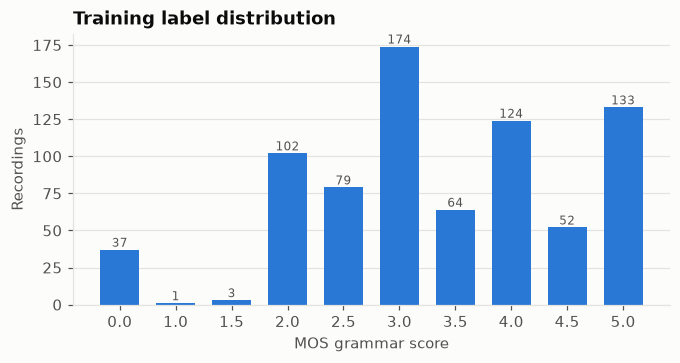

count    769.00
mean       3.31
std        1.24
min        0.00
25%        2.50
50%        3.00
75%        4.00
max        5.00


In [4]:
fig, ax = plt.subplots(figsize=(7, 3.2))
counts = train["label"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color=BLUE, width=0.7)
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8, color=INK_MUTED)
ax.set(title="Training label distribution", xlabel="MOS grammar score", ylabel="Recordings")
ax.grid(axis="x", visible=False)
plt.show()
print(train["label"].describe().round(2).to_string())

Two things stand out. Most labels sit between 2 and 5, with almost nothing at 1–1.5. There is also a separate spike
of **37 recordings scored 0**, below the rubric's lowest level, which needs explaining before any modelling.

### 1b. Data quality: the score-0 recordings are noise-corrupted audio
Listening to these files and transcribing them shows speech buried under heavy broadband noise. Whisper either
hallucinates (*"I'm sorry I'm sorry I'm sorry…"*) or recovers fragments. **Spectral flatness**, which is about 0 for
voiced speech and about 1 for white noise, separates them perfectly from every genuine recording. They also form a
separate ID block (`audio_5037`–`audio_5073`).

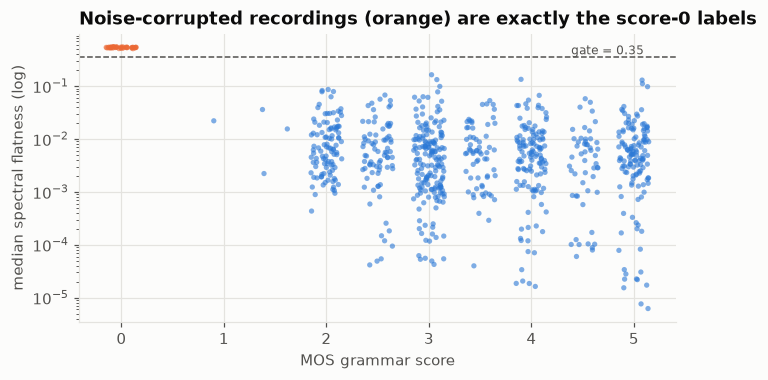

flagged by gate  False  True 
label == 0                   
False              732      0
True                 0     37

genuine max flatness = 0.164 | corrupted min = 0.511
test files flagged: 0 / 216


In [5]:
prosody = af.prosody_table(items)  # cheap acoustic statistics, needed here for the data-quality check
flat_tr = prosody.loc[train["key"], "spectral_flatness"].to_numpy()
flat_te = prosody.loc[test["key"], "spectral_flatness"].to_numpy()
gate_tr, gate_te = is_unscorable(flat_tr), is_unscorable(flat_te)

fig, ax = plt.subplots(figsize=(7, 3.4))
jitter = np.random.default_rng(0).uniform(-0.15, 0.15, len(y))
ax.scatter(y + jitter, flat_tr, s=12, alpha=0.6, color=np.where(gate_tr, ORANGE, BLUE), edgecolor="none")
ax.axhline(UNSCORABLE_FLATNESS, color=INK_MUTED, linestyle="--", linewidth=1)
ax.text(5.1, UNSCORABLE_FLATNESS, f"gate = {UNSCORABLE_FLATNESS}", va="bottom", ha="right", fontsize=8, color=INK_MUTED)
ax.set_yscale("log")
ax.set(title="Noise-corrupted recordings (orange) are exactly the score-0 labels",
       xlabel="MOS grammar score", ylabel="median spectral flatness (log)")
plt.show()

print(pd.crosstab(pd.Series(y == 0, name="label == 0"), pd.Series(gate_tr, name="flagged by gate")))
if gate_tr.any():
    print(f"\ngenuine max flatness = {flat_tr[~gate_tr].max():.3f} | corrupted min = {flat_tr[gate_tr].min():.3f}")
print(f"test files flagged: {gate_te.sum()} / {len(test)}")

**Decision.** The gate is a fixed rule, not a fitted model, and it never misfires on the training data. Flagged
recordings are predicted as **0**, and the grammar regressors are trained only on the genuine recordings. Leaving
the corrupted files in would teach the models that "noise ⇒ terrible grammar" and skew every linear model.
(The test set contains no corrupted files, but the gate keeps the engine safe on any new audio.)

The remaining labels are still imbalanced, so CV folds are **stratified by label**, with rare scores merged into
their nearest neighbour.

In [6]:
train_all, y_all = train, y                 # keep the full set for the final training-RMSE report
train = train_all[~gate_tr].reset_index(drop=True)
y = y_all[~gate_tr]
pos = {k: i for i, k in enumerate(items["key"])}  # row position of each file in the feature arrays
idx_tr = np.array([pos[k] for k in train["key"]])
idx_te = np.array([pos[k] for k in test["key"]])
print(f"genuine training recordings: {len(train)} | label mean {y.mean():.2f}, std {y.std():.2f}")

genuine training recordings: 732 | label mean 3.48, std 1.01


## 2. Speech-to-text (Whisper)

In [7]:
transcripts = transcribe.transcribe(items)["transcript"]
train_tr = transcripts.loc[train["key"]]
examples = train.assign(transcript=train_tr.values).sort_values("label")
examples.iloc[[0, len(examples) // 2, -1]][["filename", "label", "transcript"]]

,filename,label,transcript
399,audio_108.wav,1.0,As a young child one of the most exciting places to be was the playground. It was a place where the rules of classrooms and the structure environment of schools has been played well in our like th...
290,audio_245.wav,3.5,"All right. So the best day of my life is when my husband asked me to marry him. And from that time, I feel like everything has changed from this situation to up to now. So I cannot totally describ..."
612,audio_209.wav,5.0,"The best day of my life would be when I got to have my own apartment. What makes this day so special is that I've always wanted my own place, my own peace and quiet, my own space to do what I want..."


## 3. Text features

In [8]:
ling = tf.linguistic_table(items, transcripts)
gec = tf.gec_features(items, transcripts)
text_emb = tf.text_embeddings(items, transcripts)
print("linguistic:", ling.shape, "| GEC:", gec.shape, "| text embedding:", text_emb.shape)
ling.loc[train["key"]].describe().T.round(2)

linguistic: (985, 19) | GEC: (985, 3) | text embedding: (985, 768)


,count,mean,std,min,25%,50%,75%,max
n_words,732.0,99.39,26.95,24.00,81.00,100.00,120.00,155.00
n_sentences,732.0,5.60,2.83,1.00,3.00,5.00,7.00,20.00
sent_len_mean,732.0,23.78,18.82,6.12,13.98,18.00,25.33,138.00
sent_len_std,732.0,10.94,8.75,0.00,5.31,8.67,14.16,63.50
sent_len_max,732.0,41.21,22.51,11.00,25.00,35.00,51.25,138.00
mattr,732.0,0.72,0.07,0.45,0.67,0.72,0.77,0.92
avg_word_len,732.0,4.24,0.41,3.36,3.95,4.20,4.46,5.85
filler_rate,732.0,0.00,0.01,0.00,0.00,0.00,0.00,0.08
repetition_rate,732.0,0.00,0.01,0.00,0.00,0.00,0.00,0.07
dep_depth_mean,732.0,3.02,0.82,1.42,2.45,2.87,3.48,7.48


**What the GEC model changes:** original transcript and its correction for the lowest- and highest-scored recordings.

In [9]:
for fname in [examples.iloc[0]["key"], examples.iloc[-1]["key"]]:
    lab = train.set_index("key").loc[fname, "label"]
    print(f"── {fname}  label={lab}  GEC edit rate={gec.loc[fname, 'gec_edit_rate']:.1%}")
    print("ORIGINAL :", transcripts[fname][:400])
    print("CORRECTED:", gec.loc[fname, "corrected"][:400], "\n")

── train/audio_108.wav  label=1.0  GEC edit rate=2.4%
ORIGINAL : As a young child one of the most exciting places to be was the playground. It was a place where the rules of classrooms and the structure environment of schools has been played well in our like the school days we need to play very good sports in our playgrounds and we had lots of injuries in that our school time. So at the, we played a lot of things, even we had injuries in that. So we were select
CORRECTED: As a young child, one of the most exciting places to be was the playground. It was a place where the rules of classrooms and the structure environment of schools have been played well in our like the school days we need to play very good sports in our playgrounds and we had lots of injuries during that school time. So at the, we played a lot of things, even we had injuries in that. So we were sele 

── train/audio_209.wav  label=5.0  GEC edit rate=0.8%
ORIGINAL : The best day of my life would be when I got to have my 

### 3b. LLM rubric grader (Gemini)
An LLM reads each transcript *as a human rater would*. It is given the competition rubric and returns an overall
grammar score, accuracy and complexity sub-scores, an error count, and a **one-sentence rationale** naming the
errors it found. Transcripts go 25 per request (40 requests in total) at temperature 0; results are cached. The
API key is read from `.env`, never from the notebook. If no key or cache is available, this block is skipped.

In [10]:
llm_cache = config.CACHE_DIR / "llm_grades.parquet"
llm = llm_grader.llm_grades(items, transcripts) if llm_cache.exists() else None
if llm is not None:
    llm_num = llm.drop(columns="llm_rationale").astype(float)
    show = train.set_index("key").join(llm).sort_values("label")
    display(show.iloc[[0, len(show) // 2, -1]][["label", "llm_grammar_score", "llm_error_count", "llm_rationale"]])
else:
    print("LLM grades not available - continuing without them")

,label,llm_grammar_score,llm_error_count,llm_rationale
key,,,,
train/audio_108.wav,1.0,2.0,7,"Significant syntactic confusion, tense shifts, and inappropriate word collocations."
train/audio_245.wav,3.5,3.0,4,Good complex structures mixed with tense inconsistencies and wordy repetitions ('the the luckiest').
train/audio_209.wav,5.0,4.5,1,"Strong grammatical control, excellent vocabulary integration, and coherent complex sentences."


## 4. Audio features

In [11]:
wavlm = af.wavlm_embeddings(items)  # base-plus: (n_files, 13 layers, 768), mean-pooled
# large: (n_files, 25 layers, 2 * 1024) with mean + std pooling over time
wavlm_large = af.wavlm_embeddings(items, config.AUDIO_EMBED_MODEL_LARGE, "wavlm_large", with_std=True)
print("prosody:", prosody.shape, "| WavLM-base:", wavlm.shape, "| WavLM-large:", wavlm_large.shape)
prosody.loc[train["key"]].describe().T.round(2)

prosody: (985, 11) | WavLM-base: (985, 13, 768) | WavLM-large: (985, 25, 2048)


,count,mean,std,min,25%,50%,75%,max
duration_s,732.0,55.68,7.94,20.06,51.96,60.07,60.07,61.04
voiced_ratio,732.0,0.65,0.14,0.03,0.57,0.65,0.72,1.00
pauses_per_min,732.0,16.97,6.68,0.00,13.98,17.98,21.00,37.95
pause_mean_s,732.0,0.76,0.40,0.00,0.58,0.71,0.89,4.50
pause_max_s,732.0,2.18,1.89,0.00,1.15,1.68,2.69,23.46
pause_total_ratio,732.0,0.23,0.12,0.00,0.15,0.23,0.29,0.74
speech_run_mean_s,732.0,2.10,8.24,0.13,0.41,0.49,0.62,60.08
f0_mean,732.0,167.41,52.68,65.19,121.10,161.14,211.42,293.53
f0_std,732.0,30.30,14.32,0.71,19.79,29.37,38.22,97.20
rms_cv,732.0,1.13,0.32,0.16,0.96,1.08,1.24,5.64


## 5. Handcrafted feature table and interpretability
All interpretable features go into one table. Speech rate combines both modalities: words from the transcript
divided by the duration of the audio.

handcrafted features: 38


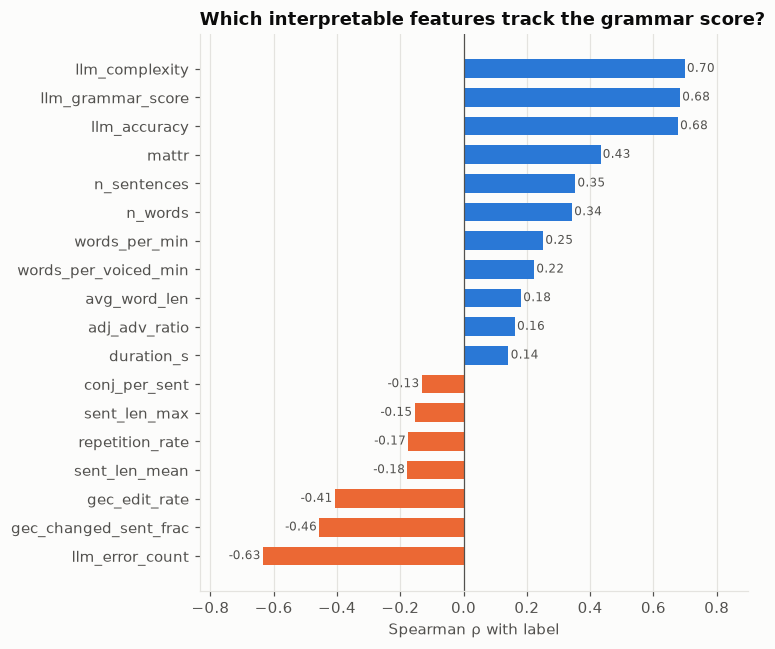

In [12]:
H = pd.concat([ling, gec[["gec_edit_rate", "gec_changed_sent_frac"]], prosody]
              + ([llm_num] if llm is not None else []), axis=1)
H["words_per_min"] = H["n_words"] / (H["duration_s"] / 60)
H["words_per_voiced_min"] = H["n_words"] / (H["duration_s"] * H["voiced_ratio"] / 60)
H = H.replace([np.inf, -np.inf], np.nan).fillna(H.median())
H_tr, H_te = H.loc[train["key"]], H.loc[test["key"]]
print("handcrafted features:", H.shape[1])

rho = pd.Series({c: spearmanr(H_tr[c], y).statistic for c in H.columns}).dropna()
top = rho.reindex(rho.abs().sort_values(ascending=False).index)[:18]
fig, ax = plt.subplots(figsize=(7, 6))
hbar(ax, top.index, top.values, "Which interpretable features track the grammar score?", "Spearman ρ with label")
plt.tight_layout(); plt.show()

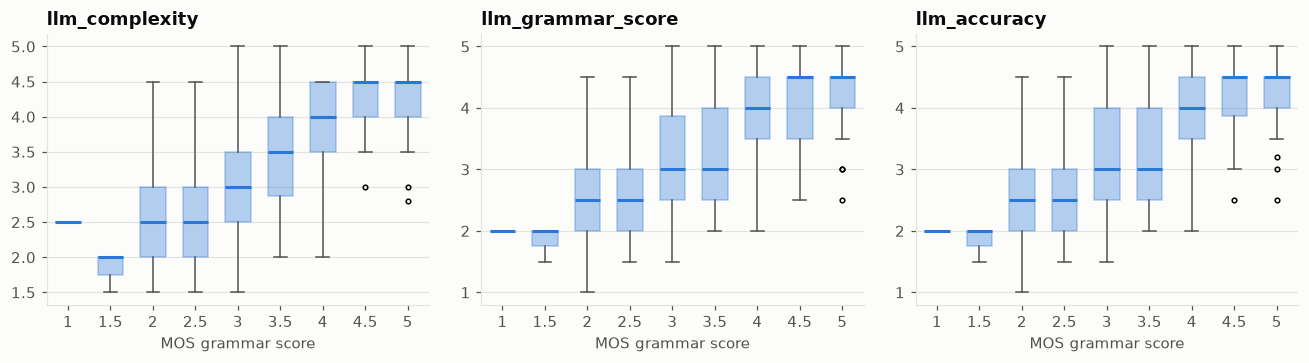

In [13]:
best = top.index[:3]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=False)
levels = np.sort(np.unique(y))
for ax, feat in zip(axes, best):
    data = [H_tr[feat].values[y == l] for l in levels]
    ax.boxplot(data, tick_labels=[f"{l:g}" for l in levels], widths=0.6, patch_artist=True,
               boxprops=dict(facecolor=BLUE, alpha=0.35, color=BLUE), medianprops=dict(color=BLUE, linewidth=2),
               whiskerprops=dict(color=INK_MUTED), capprops=dict(color=INK_MUTED), flierprops=dict(markersize=3))
    ax.set(title=feat, xlabel="MOS grammar score")
    ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

## 6. Which WavLM layer carries proficiency information?
Lower WavLM layers encode acoustics, while middle and upper layers encode phonetic and linguistic structure. A
5-fold Ridge probe on each layer shows where proficiency information lives. For modelling, **all layers are
concatenated** and Ridge learns their weights. This scored better than averaging a few chosen layers (CV RMSE 0.548
against 0.573), and because no layer is selected by hand, it cannot leak information into the CV estimate.

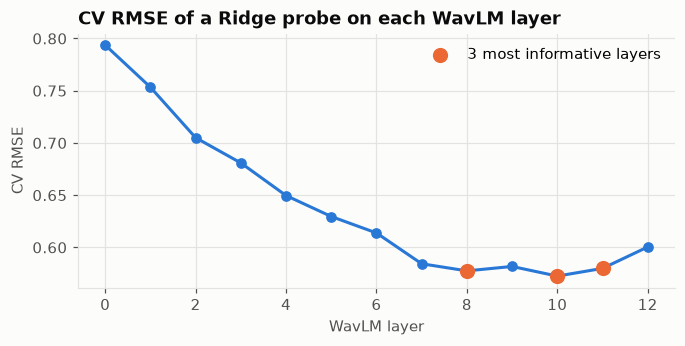

most informative layers: [8, 10, 11]


In [14]:
layer_rmse = []
for l in range(wavlm.shape[1]):
    r = cross_validate(f"L{l}", ridge, wavlm[idx_tr, l], y, n_repeats=1)
    layer_rmse.append(r.rmse)
layer_rmse = np.array(layer_rmse)
best_layers = np.argsort(layer_rmse)[:3]  # highlighted in the plot only

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(range(len(layer_rmse)), layer_rmse, color=BLUE, marker="o", markersize=6)
ax.scatter(best_layers, layer_rmse[best_layers], s=80, color=ORANGE, zorder=3, label="3 most informative layers")
ax.set(title="CV RMSE of a Ridge probe on each WavLM layer", xlabel="WavLM layer", ylabel="CV RMSE")
ax.legend(frameon=False); plt.show()
print("most informative layers:", sorted(best_layers.tolist()))

audio_emb = wavlm.reshape(len(wavlm), -1)  # all layers concatenated (n_files, 13 * 768)
H_L = wavlm_large.shape[2] // 2
large_meanstd = wavlm_large.reshape(len(wavlm_large), -1)                  # 25 layers x (mean, std) x 1024
large_mean = wavlm_large[:, :, :H_L].reshape(len(wavlm_large), -1)        # 25 layers x mean x 1024

## 7. Base models (5-fold × 3-repeat stratified CV)
One model per feature block shows how much each modality contributes on its own. The strongest block (WavLM)
also gets an RBF-kernel SVR, a non-linear model whose errors differ from Ridge's, which helps the stacker.

In [15]:
blocks = {
    "handcrafted · LightGBM": (lgbm,  H_tr.to_numpy(), H_te.to_numpy()),
    "handcrafted · Ridge":    (ridge, H_tr.to_numpy(), H_te.to_numpy()),
    "text embedding · Ridge": (ridge, text_emb[idx_tr], text_emb[idx_te]),
    "WavLM embedding · Ridge": (ridge, audio_emb[idx_tr], audio_emb[idx_te]),
    "WavLM embedding · SVR":   (svr, audio_emb[idx_tr], audio_emb[idx_te]),
    "WavLM-large mean+std · Ridge": (ridge, large_meanstd[idx_tr], large_meanstd[idx_te]),
    "WavLM-large mean · SVR":       (svr, large_mean[idx_tr], large_mean[idx_te]),
}
if llm is not None:
    blocks["LLM rubric grades · Ridge"] = (ridge, llm_num.loc[train["key"]].to_numpy(), llm_num.loc[test["key"]].to_numpy())
results = [cross_validate(name, make, X, y, X_te) for name, (make, X, X_te) in blocks.items()]
pd.DataFrame([{"model": r.name, "CV RMSE": r.rmse, "CV Pearson": r.pearson} for r in results]).round(4)

,model,CV RMSE,CV Pearson
0,handcrafted · LightGBM,0.6590,0.7601
1,handcrafted · Ridge,0.6856,0.7367
2,text embedding · Ridge,0.7459,0.6790
3,WavLM embedding · Ridge,0.5332,0.8511
4,WavLM embedding · SVR,0.5392,0.8520
5,WavLM-large mean+std · Ridge,0.4914,0.8752
6,WavLM-large mean · SVR,0.5072,0.8704
7,LLM rubric grades · Ridge,0.7322,0.6916


## 8. Stacked ensemble

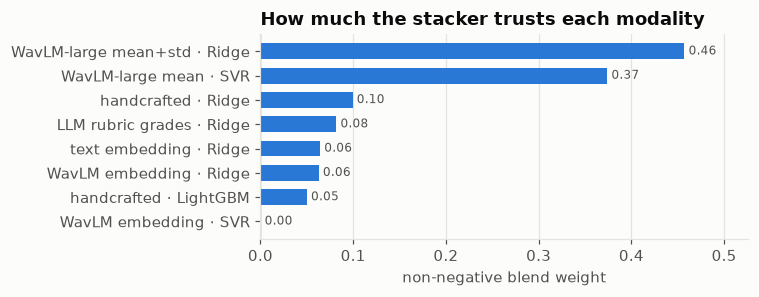

intercept=-0.652


In [16]:
ens = stack(results, y)
fig, ax = plt.subplots(figsize=(7, 2.8))
hbar(ax, list(ens.weights), list(ens.weights.values()), "How much the stacker trusts each modality", "non-negative blend weight")
plt.tight_layout(); plt.show()
print(f"intercept={ens.intercept:.3f}")

## 9. Cross-validated evaluation

In [17]:
baseline = np.full_like(y, y.mean())
# Full training set (769): the gate's fixed rule predicts 0 for corrupted files, the ensemble OOF covers the rest.
oof_all = np.zeros(len(y_all))
oof_all[~gate_tr] = ens.oof
CV_RMSE_ALL, CV_PEARSON_ALL = rmse(y_all, oof_all), pearson(y_all, oof_all)

cv_table = pd.DataFrame(
    [{"model": "baseline (predict mean)", "CV RMSE": rmse(y, baseline), "CV Pearson": np.nan}]
    + [{"model": r.name, "CV RMSE": r.rmse, "CV Pearson": r.pearson} for r in results]
    + [{"model": "STACKED ENSEMBLE (genuine recordings)", "CV RMSE": ens.rmse, "CV Pearson": ens.pearson}]
    + [{"model": "GATE + ENSEMBLE (all 769 training files)", "CV RMSE": CV_RMSE_ALL, "CV Pearson": CV_PEARSON_ALL}]
).round(4)
cv_table

,model,CV RMSE,CV Pearson
0,baseline (predict mean),1.0137,NaN
1,handcrafted · LightGBM,0.6590,0.7601
2,handcrafted · Ridge,0.6856,0.7367
3,text embedding · Ridge,0.7459,0.6790
4,WavLM embedding · Ridge,0.5332,0.8511
5,WavLM embedding · SVR,0.5392,0.8520
6,WavLM-large mean+std · Ridge,0.4914,0.8752
7,WavLM-large mean · SVR,0.5072,0.8704
8,LLM rubric grades · Ridge,0.7322,0.6916
9,STACKED ENSEMBLE (genuine recordings),0.4721,0.8850


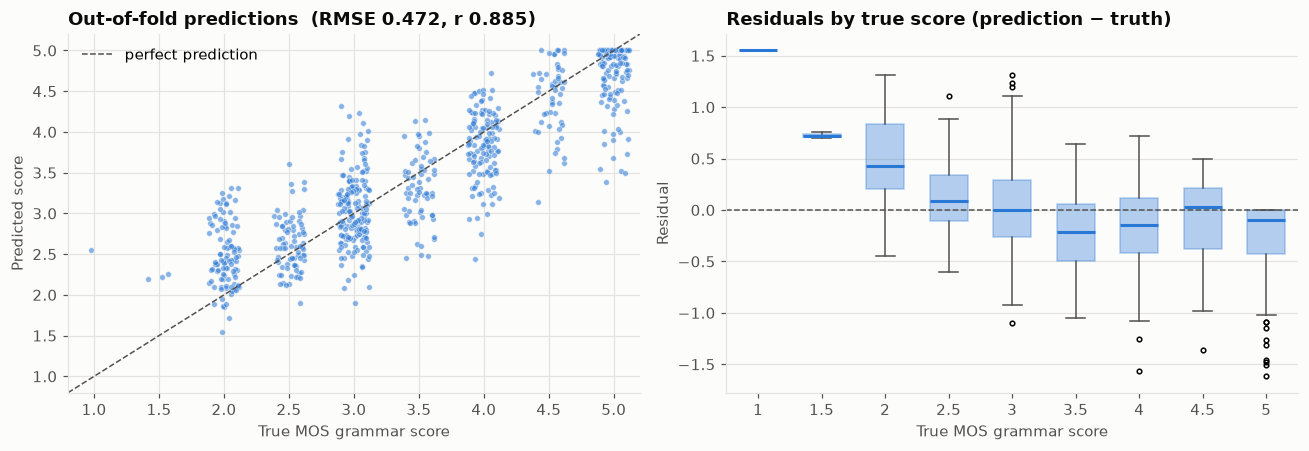

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
pred_vs_true(axes[0], y, ens.oof, f"Out-of-fold predictions  (RMSE {ens.rmse:.3f}, r {ens.pearson:.3f})")

levels = np.sort(np.unique(y))
resid = ens.oof - y
axes[1].boxplot([resid[y == l] for l in levels], tick_labels=[f"{l:g}" for l in levels], widths=0.6, patch_artist=True,
                boxprops=dict(facecolor=BLUE, alpha=0.35, color=BLUE), medianprops=dict(color=BLUE, linewidth=2),
                whiskerprops=dict(color=INK_MUTED), capprops=dict(color=INK_MUTED), flierprops=dict(markersize=3))
axes[1].axhline(0, color=INK_MUTED, linewidth=1, linestyle="--")
axes[1].set(title="Residuals by true score (prediction − truth)", xlabel="True MOS grammar score", ylabel="Residual")
axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

The residual plot shows the usual regression-to-the-mean pattern: rare extreme scores are pulled towards
the centre of the label distribution. That is expected given how few low-scored recordings there are to learn from.

## 10. Training RMSE (compulsory)
Every base model is refitted on the **full** training set, the stacker is applied, and the predictions are
scored against the training labels. This measures fit, not generalisation; the CV numbers above are the honest
estimate of test performance.

In [19]:
full_models = {name: clone(make()).fit(X, y) for name, (make, X, _) in blocks.items()}
train_base = np.column_stack([full_models[name].predict(X) for name, (_, X, _) in blocks.items()])
train_pred = np.clip(ens.stacker.predict(train_base), 0, 5)
train_pred_all = np.zeros(len(y_all))
train_pred_all[~gate_tr] = train_pred          # corrupted recordings -> 0 via the gate

TRAIN_RMSE, TRAIN_PEARSON = rmse(y_all, train_pred_all), pearson(y_all, train_pred_all)
print(f"TRAINING RMSE    (all {len(y_all)} files) = {TRAIN_RMSE:.4f}")
print(f"TRAINING Pearson (all {len(y_all)} files) = {TRAIN_PEARSON:.4f}")

summary = pd.DataFrame({
    "RMSE":    [TRAIN_RMSE, rmse(y, train_pred), CV_RMSE_ALL, ens.rmse],
    "Pearson": [TRAIN_PEARSON, pearson(y, train_pred), CV_PEARSON_ALL, ens.pearson],
}, index=["TRAINING - all files (gate + full-fit ensemble)", "training - genuine recordings only",
          "cross-validation - all files", "cross-validation - genuine recordings only"]).round(4)
summary

TRAINING RMSE    (all 769 files) = 0.1614
TRAINING Pearson (all 769 files) = 0.9915


,RMSE,Pearson
TRAINING - all files (gate + full-fit ensemble),0.1614,0.9915
training - genuine recordings only,0.1654,0.9867
cross-validation - all files,0.4606,0.9283
cross-validation - genuine recordings only,0.4721,0.8850


## 11. Explaining the handcrafted model (SHAP)
LightGBM computes exact TreeSHAP contributions (`pred_contrib=True`). The mean absolute contribution gives global
importance, and a single recording's contributions explain why it received its score.

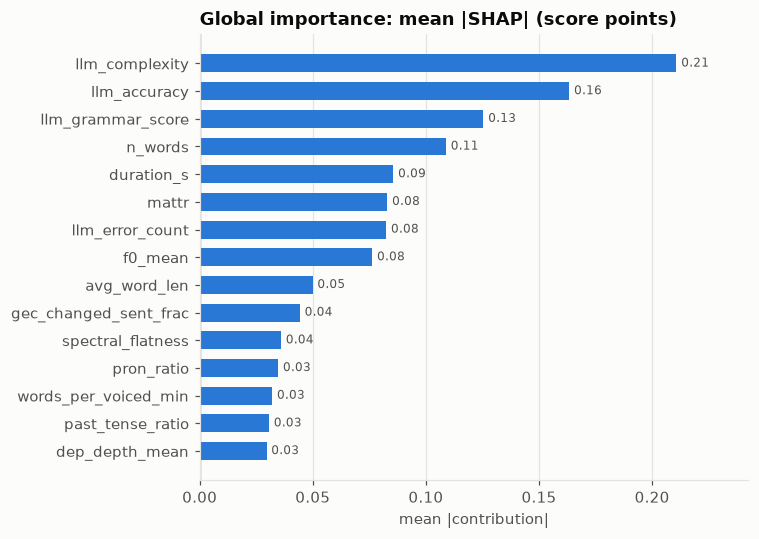

In [20]:
lgb_full = full_models["handcrafted · LightGBM"]
contrib = lgb_full.predict(H_tr.to_numpy(), pred_contrib=True)[:, :-1]  # last column = expected value
shap_imp = pd.Series(np.abs(contrib).mean(0), index=H.columns).sort_values(ascending=False)[:15]
fig, ax = plt.subplots(figsize=(7, 5))
hbar(ax, shap_imp.index, shap_imp.values, "Global importance: mean |SHAP| (score points)", "mean |contribution|")
plt.tight_layout(); plt.show()

In [21]:
def explain(fname, k=6):
    i = train.index[train["key"] == fname][0]
    c = pd.Series(contrib[i], index=H.columns)
    c = c.reindex(c.abs().sort_values(ascending=False).index)[:k]
    print(f"{fname}: true={y[i]:g}  LightGBM={lgb_full.predict(H_tr.to_numpy()[i:i+1])[0]:.2f}  ensemble={train_pred[i]:.2f}")
    for f, v in c.items():
        print(f"   {f:<26} value={H_tr.iloc[i][f]:>8.3f}   contribution={v:+.3f}")

explain(examples.iloc[0]["key"]); print()
explain(examples.iloc[-1]["key"])

train/audio_108.wav: true=1  LightGBM=1.69  ensemble=1.22
   llm_complexity             value=   2.500   contribution=-0.315
   llm_grammar_score          value=   2.000   contribution=-0.203
   llm_accuracy               value=   2.000   contribution=-0.192
   duration_s                 value=  45.060   contribution=-0.192
   spectral_flatness          value=   0.022   contribution=-0.134
   past_tense_ratio           value=   0.571   contribution=-0.116

train/audio_209.wav: true=5  LightGBM=4.88  ensemble=5.00
   llm_complexity             value=   4.000   contribution=+0.337
   llm_accuracy               value=   4.500   contribution=+0.230
   llm_grammar_score          value=   4.500   contribution=+0.194
   n_words                    value= 120.000   contribution=+0.147
   f0_mean                    value= 157.608   contribution=+0.126
   llm_error_count            value=   1.000   contribution=+0.105


## 12. Test predictions and submission file

saved /Users/arnav/Desktop/pro/submissions/submission.csv (216, 2)


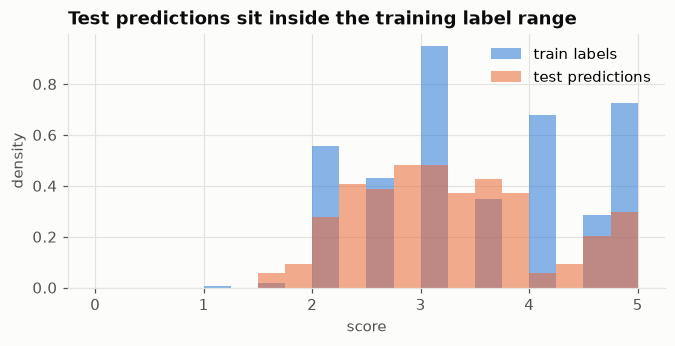

,filename,label
0,audio_128.wav,2.782563
1,audio_156.wav,4.332140
2,audio_19.wav,4.607230
3,audio_108.wav,1.847566
4,audio_206.wav,2.110864


In [22]:
# Columns follow sample_submission.csv; rows follow test.csv (sample_submission's filenames are placeholders).
sub_cols = list(ds.sample_submission.columns) if ds.sample_submission is not None else ["filename", "label"]
final_test = np.where(gate_te, 0.0, ens.test)  # gate first, then the grammar ensemble
submission = pd.DataFrame({sub_cols[0]: test["filename"].values, sub_cols[1]: final_test})
out = config.SUBMISSION_DIR / "submission.csv"
submission.to_csv(out, index=False)
print("saved", out, submission.shape)

fig, ax = plt.subplots(figsize=(7, 3))
bins = np.arange(0, 5.25, 0.25)
ax.hist(y, bins=bins, color=BLUE, alpha=0.55, label="train labels", density=True)
ax.hist(final_test, bins=bins, color=ORANGE, alpha=0.55, label="test predictions", density=True)
ax.set(title="Test predictions sit inside the training label range", xlabel="score", ylabel="density")
ax.legend(frameon=False); plt.show()
submission.head()

## 13. Conclusions and limitations
* **Audio embeddings carry the most signal.** WavLM-large, with every layer concatenated and mean + std pooling, is the
  strongest single model (CV RMSE 0.491). It captures proficiency cues such as hesitation, rhythm and phrasing,
  which the transcript loses, and it is immune to Whisper "tidying up" the speaker's errors.
* **Text features make the result explainable and still add accuracy.** The GEC edit rate, syntactic complexity and
  the Gemini rubric grades line up with the rubric. Adding them improves the ensemble, and they explain *why* a
  recording scored low (Section 11, plus the LLM rationales).
* **Checking the data mattered as much as modelling.** The 37 noise-corrupted "score 0" files and the 212 filenames
  shared between train/ and test/ would each have silently corrupted training if they had not been caught.
* **Limitations.** Whisper sometimes normalises disfluent speech, which understates errors. Very few training scores
  are below 2, so predictions for very weak speakers are pulled upwards (see the residual plot). The high-dimensional
  embedding models fit the training set closely (training RMSE 0.16 against CV 0.47); CV is the honest estimate.
* **Next steps.** Fine-tune WavLM-large end-to-end on a GPU; add Whisper-encoder embeddings; average over several
  CV seeds; build a rubric-specific error taxonomy (tense, articles, agreement) from the LLM rationales.